In [ ]:
pip install requests pandas

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import json
import time
import sqlite3
import logging
from datetime import datetime
import requests
import pandas as pd
import numpy as np
from google.colab import drive # <-- Adicionado para garantir a conexão

# 1. Montar o Google Drive (garante persistência dos dados)
drive.mount('/content/drive')

# Configurações da API CKAN Recife
BASE_API_URL = "https://dados.recife.pe.gov.br/api/3/action"
DATASET_ID = "acidentes-de-transito-com-e-sem-vitimas"
TARGET_YEAR = "2024"

# 2. CORREÇÃO CRÍTICA: Redirecionar os caminhos para o Google Drive
DRIVE_BASE_PATH = "/content/drive/MyDrive/Backup_ETL1_Recife"
os.makedirs(DRIVE_BASE_PATH, exist_ok=True)

# Agora os caminhos apontam para o Drive, não para a memória temporária
DIR_RAW = os.path.join(DRIVE_BASE_PATH, "raw")
DIR_PROCESSED = os.path.join(DRIVE_BASE_PATH, "processed")
DIR_REPORTS = os.path.join(DRIVE_BASE_PATH, "reports")
DB_PATH = os.path.join(DRIVE_BASE_PATH, "mobilidade_recife.db")

# Criação dos diretórios no Drive
for directory in [DIR_RAW, DIR_PROCESSED, DIR_REPORTS]:
    os.makedirs(directory, exist_ok=True)

# Configuração de Logs (salvando o log também no Drive)
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s [%(levelname)s] %(message)s",
    handlers=[
        logging.FileHandler(f"{DIR_REPORTS}/etl_01_execution.log", mode="w", encoding="utf-8"),
        logging.StreamHandler()
    ]
)

print("="*60)
print("✅ BLOCO 3 CARREGADO COM SUCESSO!")
print(f"📁 Os dados brutos, tratados e o banco serão salvos em:")
print(f"   {DRIVE_BASE_PATH}")
print("="*60)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ BLOCO 3 CARREGADO COM SUCESSO!
📁 Os dados brutos, tratados e o banco serão salvos em:
   /content/drive/MyDrive/Backup_ETL1_Recife


In [ ]:
def discover_resource_2024(dataset_id: str, year: str) -> dict:
    """Localiza o resource_id de 2024 via package_show e gera o catálogo de metadados."""
    url = f"{BASE_API_URL}/package_show"
    logging.info(f"Consultando metadados do conjunto: {dataset_id}")

    response = requests.get(url, params={"id": dataset_id}, timeout=30)
    response.raise_for_status()
    data = response.json()

    if not data.get("success") or "result" not in data:
        raise ValueError("Resposta inválida da API CKAN no endpoint package_show.")

    pkg = data["result"]
    target_resource = None

    for res in pkg.get("resources", []):
        name = str(res.get("name", "")).lower()
        desc = str(res.get("description", "")).lower()
        url_res = str(res.get("url", "")).lower()
        if year in name or year in desc or year in url_res:
            target_resource = res
            break

    if not target_resource:
        raise LookupError(f"Recurso do ano {year} não encontrado no dataset {dataset_id}.")

    catalog_metadata = {
        "ref_fonte": "S1",
        "dataset_id": pkg.get("name"),
        "dataset_title": pkg.get("title"),
        "resource_id": target_resource.get("id"),
        "resource_name": target_resource.get("name"),
        "format": target_resource.get("format"),
        "datastore_active": target_resource.get("datastore_active"),
        "resource_url": target_resource.get("url"),
        "license": pkg.get("license_title", "Dados Abertos Recife"),
        "resource_created": target_resource.get("created"),
        "resource_last_modified": target_resource.get("last_modified"),
        "extraction_timestamp": datetime.now().isoformat(),
        "recorte_temporal": year
    }

    catalog_path = f"{DIR_REPORTS}/catalogo_fonte_S1_{year}.json"
    with open(catalog_path, "w", encoding="utf-8") as f:
        json.dump(catalog_metadata, f, indent=4, ensure_ascii=False)

    logging.info(f"Recurso 2024 localizado! ID: {catalog_metadata['resource_id']}")
    return catalog_metadata

print("Bloco 2 carregado com sucesso!")

Bloco 2 carregado com sucesso!


In [ ]:
import io

def extract_ckan_paginated(metadata: dict, limit: int = 10000) -> pd.DataFrame:
    """
    Coleta todos os registros de 2024.
    ESTRATÉGIA: Tenta download direto do CSV primeiro (mais rápido e estável).
    Se falhar, usa paginação no DataStore como fallback.
    """
    resource_id = metadata["resource_id"]
    resource_url = metadata["resource_url"]

    logging.info(f"Resource ID: {resource_id}")
    logging.info(f"Tentando extração dos dados...")

    # ESTRATÉGIA 1: Download direto do arquivo CSV (Recomendado)
    try:
        logging.info("Tentando download direto do CSV via URL...")
        headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'}

        # Aumentamos o timeout para 60s para garantir o download de arquivos maiores
        resp = requests.get(resource_url, headers=headers, timeout=60, allow_redirects=True)
        resp.raise_for_status()

        # Detecta encoding para evitar erros de caracteres especiais (ex: ç, ã)
        encoding = 'utf-8-sig' if 'charset=utf-8' in resp.headers.get('Content-Type', '').lower() else 'utf-8'

        # Lê o CSV diretamente da memória
        df_raw = pd.read_csv(io.StringIO(resp.text), sep=None, engine='python', encoding=encoding)

        logging.info(f"✅ SUCESSO: Download direto concluído! Total de registros: {len(df_raw)}")

    except Exception as e:
        logging.warning(f"Download direto falhou ({e}). Ativando fallback via DataStore API...")

        # ESTRATÉGIA 2: Fallback via DataStore com paginação robusta
        url = f"{BASE_API_URL}/datastore_search"
        all_records = []
        offset = 0
        total_expected = None

        while True:
            params = {"resource_id": resource_id, "limit": limit, "offset": offset}
            resp = requests.get(url, params=params, timeout=60)
            resp.raise_for_status()
            payload = resp.json()

            if not payload.get("success") or "result" not in payload:
                raise ValueError(f"Falha na resposta da API em offset={offset}")

            result = payload["result"]
            records = result.get("records", [])

            if total_expected is None:
                total_expected = result.get("total", 0)
                logging.info(f"⚠️ API informa que o total esperado é: {total_expected} registros.")

            if not records:
                break

            all_records.extend(records)
            logging.info(f"Página coletada: offset={offset} | Acumulado: {len(all_records)}/{total_expected}")

            offset += limit
            if len(records) < limit or len(all_records) >= total_expected:
                break
            time.sleep(0.3) # Pausa leve para não sobrecarregar a API

        df_raw = pd.DataFrame(all_records)
        logging.info(f"✅ SUCESSO: Fallback DataStore concluído! Total de registros: {len(df_raw)}")

    # Salva cópia bruta (Preservação dos dados originais - Regra de Ouro)
    raw_csv_path = f"{DIR_RAW}/s1_chamados_sinistros_{TARGET_YEAR}_raw.csv"
    df_raw.to_csv(raw_csv_path, index=False, encoding="utf-8-sig")
    logging.info(f"💾 Arquivo bruto preservado em: {raw_csv_path}")

    return df_raw

print("✅ Bloco 5 (Extração Robusta) carregado com sucesso!")

✅ Bloco 5 (Extração Robusta) carregado com sucesso!


In [ ]:
def standardize_column_names(df: pd.DataFrame) -> pd.DataFrame:
    """
    Padroniza os nomes das colunas essenciais garantindo que NÃO existam
    colunas duplicadas (o que transformaria df['col'] em DataFrame).
    """
    df = df.copy()

    # Mapeamento de prioridade para cada coluna essencial
    candidates = {
        "protocolo": ["protocolo", "numprotocolo", "nprotocolo"],
        "data": ["data", "dataacidente", "dataocorrencia", "dataabertura"],
        "hora": ["hora", "horaacidente", "horaocorrencia", "horaabertura"],
        "bairro": ["bairro"],
        "tipo": ["tipo", "naturezaacidente", "natureza", "tipoacidente", "tipoocorrencia"],
        "vitimas": ["vitimas", "numvitimas", "qtdvitimas"],
        "vitimasfatais": ["vitimasfatais", "numvitimasfatais", "qtdvitimasfatais"]
    }

    # Dicionário auxiliar: nome_limpo -> nome_original_na_base
    clean_to_orig = {}
    for col in df.columns:
        c_clean = col.strip().lower().replace("_", "").replace(" ", "")
        if c_clean not in clean_to_orig:
            clean_to_orig[c_clean] = col

    # Seleciona apenas a primeira coluna correspondente de maior prioridade
    for target_col, alias_list in candidates.items():
        found_orig = None
        for alias in alias_list:
            if alias in clean_to_orig:
                found_orig = clean_to_orig[alias]
                break

        if found_orig is not None:
            # Se a coluna original tiver outro nome, copia para o nome padrão
            if found_orig != target_col:
                df[target_col] = df[found_orig]
        else:
            df[target_col] = np.nan

    # Remove eventuais colunas duplicadas com o mesmo nome exato
    df = df.loc[:, ~df.columns.duplicated()].copy()
    return df


def audit_and_clean_numeric(series: pd.Series, col_name: str) -> tuple:
    """Separa zeros válidos, positivos, nulos/não informados e inválidos (usando Int64)."""
    # Garante que series é 1D (Series)
    if isinstance(series, pd.DataFrame):
        series = series.iloc[:, 0]

    s_raw = series.copy()
    missing_tokens = ["", "nan", "none", "null", "s/i", "si", "nao informado", "não informado", "-", "n/a", "<na>"]

    s_str = s_raw.astype(str).str.strip().str.lower()
    is_missing = s_raw.isna() | s_str.isin(missing_tokens)

    s_num = pd.to_numeric(s_str.str.replace(",", ".", regex=False), errors="coerce")
    is_invalid = (~is_missing) & (s_num.isna() | (s_num < 0) | (s_num % 1 != 0))

    s_clean = s_num.mask(is_missing | is_invalid, np.nan).astype("Int64")
    was_corrected = is_invalid | ((~is_missing) & (s_raw.astype(str) != s_clean.astype(str)))

    audit_stats = {
        "campo": col_name,
        "total_registros": int(len(s_raw)),
        "zeros_validos": int((s_clean == 0).fillna(False).sum()),
        "positivos_validos": int((s_clean > 0).fillna(False).sum()),
        "nulos_ou_nao_informados_origem": int(is_missing.sum()),
        "invalidos_convertidos_para_nulo": int(is_invalid.sum()),
        "total_nulos_pos_tratamento": int(s_clean.isna().sum())
    }
    return s_clean, audit_stats, was_corrected


def derive_faixa_horaria(hora_series: pd.Series) -> tuple:
    """Padroniza a hora e classifica na faixa horária (compatível com Python 3.13 / NumPy 2.0)."""
    if isinstance(hora_series, pd.DataFrame):
        hora_series = hora_series.iloc[:, 0]

    s_str = hora_series.astype(str).str.strip()
    extracted_hour = s_str.str.extract(r"^(\d{1,2})[:h]", expand=False)
    hour_num = pd.to_numeric(extracted_hour, errors="coerce")
    hour_num = hour_num.where((hour_num >= 0) & (hour_num <= 23), np.nan).astype("Int64")

    hora_pad = pd.to_datetime(s_str, format="%H:%M:%S", errors="coerce").dt.strftime("%H:%M:%S")
    hora_pad = hora_pad.fillna(pd.to_datetime(s_str, format="%H:%M", errors="coerce").dt.strftime("%H:%M:00"))

    # Converte para bool do NumPy evitando erro com <NA> no Python 3.13
    conditions = [
        hour_num.isna().to_numpy(dtype=bool),
        hour_num.between(0, 5).fillna(False).to_numpy(dtype=bool),
        hour_num.between(6, 11).fillna(False).to_numpy(dtype=bool),
        hour_num.between(12, 17).fillna(False).to_numpy(dtype=bool),
        hour_num.between(18, 23).fillna(False).to_numpy(dtype=bool)
    ]
    choices = [
        "Não Informada",
        "00h-05h (Madrugada)",
        "06h-11h (Manhã)",
        "12h-17h (Tarde)",
        "18h-23h (Noite)"
    ]
    faixa = pd.Series(np.select(conditions, choices, default="Não Informada"), index=hora_series.index)
    return hora_pad, hour_num, faixa

print("Bloco 4 carregado com sucesso!")

Bloco 4 carregado com sucesso!


In [ ]:
def transform_chamados(df_raw: pd.DataFrame) -> tuple:
    """Executa a limpeza, investigação de duplicatas, derivações temporais e auditoria."""
    logging.info("Iniciando etapa de validação e transformação...")
    df = standardize_column_names(df_raw)

    if "_id" in df.columns:
        df = df.drop(columns=["_id"])

    linhas_lidas = len(df)
    essential_cols = ["protocolo", "data", "hora", "bairro", "tipo", "vitimas", "vitimasfatais"]
    corrected_mask = pd.Series(False, index=df.index)

    def clean_text_col(s: pd.Series, invalid_tokens: list) -> tuple:
        orig = s.copy()
        s_clean = s.astype(str).str.strip().str.title().str.replace(r"\s+", " ", regex=True)
        is_null = orig.isna() | s_clean.isin(invalid_tokens)
        s_clean = s_clean.mask(is_null, np.nan)
        changed = (~orig.isna()) & (orig.astype(str) != s_clean.fillna(""))
        return s_clean, changed

    null_tokens = ["", "NAN", "NONE", "NULL", "NÃO INFORMADO", "NAO INFORMADO", "S/I", "SI", "-", "0", "S/B", "SEM BAIRRO"]

    df["protocolo"], chg_prot = clean_text_col(df["protocolo"], ["", "NAN", "NONE", "NULL", "-", "0"])
    df["bairro"], chg_bairro = clean_text_col(df["bairro"], null_tokens)
    df["tipo"], chg_tipo = clean_text_col(df["tipo"], null_tokens)
    corrected_mask |= (chg_prot | chg_bairro | chg_tipo)

    # Investigação de Protocolos Repetidos ANTES de deduplicar
    exact_dups_mask = df.duplicated(subset=essential_cols, keep="first")
    qtd_duplicatas_exatas = int(exact_dups_mask.sum())

    valid_prot_mask = df["protocolo"].notna()
    prot_dups_mask = valid_prot_mask & df.duplicated(subset=["protocolo"], keep=False)
    grupos_protocolos_repetidos = int(df.loc[prot_dups_mask, "protocolo"].nunique())
    total_linhas_prot_repetido = int((valid_prot_mask & df.duplicated(subset=["protocolo"], keep="first")).sum())
    qtd_duplicatas_conflitantes = max(0, total_linhas_prot_repetido - qtd_duplicatas_exatas)

    dup_investigation = {
        "total_linhas_lidas": linhas_lidas,
        "grupos_de_protocolos_repetidos": grupos_protocolos_repetidos,
        "linhas_excedentes_por_protocolo_repetido": total_linhas_prot_repetido,
        "duplicatas_exatas_todos_campos": qtd_duplicatas_exatas,
        "duplicatas_mesmo_protocolo_campos_divergentes": qtd_duplicatas_conflitantes
    }

    # Ordena para manter o registro mais completo na deduplicação
    df["_qtd_nulos_essenciais"] = df[essential_cols].isna().sum(axis=1)
    df = df.sort_values(by=["protocolo", "_qtd_nulos_essenciais"], ascending=[True, True])

    is_dup_protocol = df["protocolo"].notna() & df.duplicated(subset=["protocolo"], keep="first")
    is_missing_protocol = df["protocolo"].isna()

    parsed_date = pd.to_datetime(df["data"], errors="coerce", format="mixed")
    is_invalid_date = parsed_date.isna() | (parsed_date.dt.year != int(TARGET_YEAR))

    rejected_mask = is_missing_protocol | is_dup_protocol | is_invalid_date
    linhas_rejeitadas = int(rejected_mask.sum())

    df_valid = df[~rejected_mask].copy()
    corrected_mask_valid = corrected_mask.loc[df_valid.index].copy()
    df_valid["data_evento"] = parsed_date.loc[df_valid.index].dt.strftime("%Y-%m-%d")

    # Campos numéricos
    df_valid["vitimas"], audit_vitimas, corr_vit = audit_and_clean_numeric(df_valid["vitimas"], "vitimas")
    df_valid["vitimasfatais"], audit_vitimas_fatais, corr_vit_fat = audit_and_clean_numeric(df_valid["vitimasfatais"], "vitimasfatais")
    corrected_mask_valid |= (corr_vit | corr_vit_fat)

    # Colunas derivadas: mês, dia da semana e faixa horária
    dt_series = pd.to_datetime(df_valid["data_evento"])
    meses_pt = {
        1: "01 - Janeiro", 2: "02 - Fevereiro", 3: "03 - Março", 4: "04 - Abril",
        5: "05 - Maio", 6: "06 - Junho", 7: "07 - Julho", 8: "08 - Agosto",
        9: "09 - Setembro", 10: "10 - Outubro", 11: "11 - Novembro", 12: "12 - Dezembro"
    }
    dias_semana_pt = {
        0: "Segunda-feira", 1: "Terça-feira", 2: "Quarta-feira", 3: "Quinta-feira",
        4: "Sexta-feira", 5: "Sábado", 6: "Domingo"
    }

    df_valid["mes_num"] = dt_series.dt.month.astype("Int64")
    df_valid["mes"] = df_valid["mes_num"].map(meses_pt)
    df_valid["dia_semana_num"] = dt_series.dt.dayofweek.astype("Int64")
    df_valid["dia_semana"] = df_valid["dia_semana_num"].map(dias_semana_pt)

    hora_pad, hora_num, faixa_horaria = derive_faixa_horaria(df_valid["hora"])
    corr_hora = df_valid["hora"].notna() & (df_valid["hora"].astype(str).str.strip() != hora_pad.fillna(""))
    corrected_mask_valid |= corr_hora

    df_valid["hora"] = hora_pad
    df_valid["hora_num"] = hora_num
    df_valid["faixa_horaria"] = faixa_horaria

    linhas_corrigidas = int(corrected_mask_valid.sum())
    linhas_carregadas = len(df_valid)

    # Taxa de nulos nos campos essenciais
    null_rates = []
    for col in essential_cols:
        nulos_brutos = int(df[col].isna().sum())
        nulos_finais = int(df_valid[col].isna().sum())
        null_rates.append({
            "campo_essencial": col,
            "nulos_base_lida": nulos_brutos,
            "taxa_nulos_lida_%": round((nulos_brutos / linhas_lidas) * 100, 2) if linhas_lidas else 0.0,
            "nulos_base_carregada": nulos_finais,
            "taxa_nulos_carregada_%": round((nulos_finais / linhas_carregadas) * 100, 2) if linhas_carregadas else 0.0
        })

    quality_summary = {
        "fonte": "S1 - Acidentes de Trânsito 2024",
        "linhas_lidas": linhas_lidas,
        "linhas_rejeitadas": linhas_rejeitadas,
        "rejeitadas_duplicata_protocolo": int(is_dup_protocol.sum()),
        "rejeitadas_protocolo_nulo": int(is_missing_protocol.sum()),
        "rejeitadas_data_invalida_ou_fora_2024": int((~is_missing_protocol & ~is_dup_protocol & is_invalid_date).sum()),
        "linhas_corrigidas": linhas_corrigidas,
        "linhas_carregadas": linhas_carregadas
    }

    audit_artifacts = {
        "quality_summary": quality_summary,
        "dup_investigation": dup_investigation,
        "numeric_audit": [audit_vitimas, audit_vitimas_fatais],
        "null_rates": pd.DataFrame(null_rates)
    }
    return df_valid, audit_artifacts

print("Bloco 5 carregado com sucesso!")

Bloco 5 carregado com sucesso!


In [ ]:
def build_and_load_star_schema(df_valid: pd.DataFrame, metadata: dict):
    """Carrega fato_chamados e dimensões de tempo, bairro e fonte em SQLite e CSV."""
    logging.info("Construindo modelo dimensional...")

    # Dimensão Bairro
    bairros_unicos = sorted(df_valid["bairro"].dropna().unique())
    dim_bairro = pd.DataFrame({"bairro": bairros_unicos})
    dim_bairro.insert(0, "id_bairro", range(1, len(dim_bairro) + 1))
    dim_bairro = pd.concat([pd.DataFrame([{"id_bairro": -1, "bairro": "NÃO INFORMADO"}]), dim_bairro], ignore_index=True)

    # Dimensão Tempo
    cols_tempo = ["data_evento", "mes_num", "mes", "dia_semana_num", "dia_semana"]
    dim_tempo = df_valid[cols_tempo].drop_duplicates().sort_values("data_evento").reset_index(drop=True)
    dim_tempo.insert(0, "id_tempo", dim_tempo["data_evento"].str.replace("-", "").astype(int))

    # Dimensão Fonte
    dim_fonte = pd.DataFrame([metadata])

    # Fato Chamados
    fato = df_valid.merge(dim_bairro, on="bairro", how="left")
    fato["id_bairro"] = fato["id_bairro"].fillna(-1).astype(int)
    fato["id_tempo"] = fato["data_evento"].str.replace("-", "").astype(int)
    fato["resource_id"] = metadata["resource_id"]

    cols_fato = [
        "protocolo", "id_tempo", "id_bairro", "data_evento", "hora",
        "faixa_horaria", "mes_num", "mes", "dia_semana", "bairro",
        "tipo", "vitimas", "vitimasfatais", "resource_id"
    ]
    fato_chamados = fato[cols_fato].copy()

    with sqlite3.connect(DB_PATH) as conn:
        dim_fonte.to_sql("dim_fonte", conn, if_exists="replace", index=False)
        dim_bairro.to_sql("dim_bairro", conn, if_exists="replace", index=False)
        dim_tempo.to_sql("dim_tempo", conn, if_exists="replace", index=False)
        fato_chamados.to_sql("fato_chamados", conn, if_exists="replace", index=False)

    fato_chamados.to_csv(f"{DIR_PROCESSED}/fato_chamados_2024.csv", index=False, encoding="utf-8-sig")
    dim_bairro.to_csv(f"{DIR_PROCESSED}/dim_bairro.csv", index=False, encoding="utf-8-sig")
    dim_tempo.to_csv(f"{DIR_PROCESSED}/dim_tempo.csv", index=False, encoding="utf-8-sig")
    logging.info("Carga concluída no banco SQLite e em arquivos CSV.")

print("Bloco 6 carregado com sucesso!")

Bloco 6 carregado com sucesso!


In [ ]:
def generate_indicators_and_reports(df_valid: pd.DataFrame, audit_artifacts: dict):
    """Calcula os indicadores do ETL 1 e imprime o relatório de qualidade."""
    total_carregados = len(df_valid)
    sem_bairro_count = int(df_valid["bairro"].isna().sum())
    pct_sem_bairro = round((sem_bairro_count / total_carregados) * 100, 2) if total_carregados else 0.0

    df_temp = df_valid.copy()
    df_temp["bairro_analise"] = df_temp["bairro"].fillna("SEM BAIRRO INFORMADO")

    # Indicador 1: Chamados por mês e bairro
    ind_mes_bairro = (
        df_temp.groupby(["mes_num", "mes", "bairro_analise"], as_index=False)
        .agg(
            qtd_chamados=("protocolo", "count"),
            soma_vitimas_informadas=("vitimas", "sum"),
            soma_vitimas_fatais_informadas=("vitimasfatais", "sum")
        )
        .sort_values(["mes_num", "qtd_chamados"], ascending=[True, False])
    )
    ind_mes_bairro.to_csv(f"{DIR_REPORTS}/indicador_chamados_por_mes_bairro.csv", index=False, encoding="utf-8-sig")

    # Ranking por Bairro
    ind_ranking_bairro = (
        df_temp.groupby("bairro_analise", as_index=False)
        .agg(qtd_chamados=("protocolo", "count"), soma_vitimas_informadas=("vitimas", "sum"))
        .sort_values("qtd_chamados", ascending=False)
    )
    ind_ranking_bairro["participacao_%"] = round((ind_ranking_bairro["qtd_chamados"] / total_carregados) * 100, 2)
    ind_ranking_bairro.to_csv(f"{DIR_REPORTS}/indicador_ranking_bairros_2024.csv", index=False, encoding="utf-8-sig")

    # Chamados por Faixa Horária
    ind_faixa_horaria = (
        df_temp.groupby("faixa_horaria", as_index=False)
        .agg(qtd_chamados=("protocolo", "count"), soma_vitimas_informadas=("vitimas", "sum"))
        .sort_values("qtd_chamados", ascending=False)
    )
    ind_faixa_horaria["participacao_%"] = round((ind_faixa_horaria["qtd_chamados"] / total_carregados) * 100, 2)
    ind_faixa_horaria.to_csv(f"{DIR_REPORTS}/indicador_chamados_faixa_horaria_2024.csv", index=False, encoding="utf-8-sig")

    # Soma de vítimas informadas
    vit_n = int(df_valid["vitimas"].notna().sum())
    vit_fat_n = int(df_valid["vitimasfatais"].notna().sum())
    soma_vitimas = int(df_valid["vitimas"].sum(skipna=True))
    soma_vitimas_fatais = int(df_valid["vitimasfatais"].sum(skipna=True))

    # Salva relatórios de qualidade
    pd.DataFrame([audit_artifacts["quality_summary"]]).to_csv(f"{DIR_REPORTS}/relatorio_qualidade_resumo.csv", index=False, encoding="utf-8-sig")
    audit_artifacts["null_rates"].to_csv(f"{DIR_REPORTS}/relatorio_qualidade_nulos.csv", index=False, encoding="utf-8-sig")

    print("\n" + "=" * 80)
    print("RELATÓRIO DE QUALIDADE E INDICADORES - ETL 1 (SINISTROS 2024)")
    print("=" * 80)
    print("\n1. RESUMO DE QUALIDADE (LIDAS, REJEITADAS, CORRIGIDAS E CARREGADAS):")
    for k, v in audit_artifacts["quality_summary"].items():
        print(f"   - {k}: {v}")

    print("\n2. INVESTIGAÇÃO DE PROTOCOLOS REPETIDOS:")
    for k, v in audit_artifacts["dup_investigation"].items():
        print(f"   - {k}: {v}")

    print("\n3. AUDITORIA DE CAMPOS NUMÉRICOS (ZEROS VÁLIDOS VS NULOS/INVÁLIDOS):")
    print(pd.DataFrame(audit_artifacts["numeric_audit"]).to_string(index=False))

    print("\n4. TAXA DE NULOS NOS CAMPOS ESSENCIAIS:")
    print(audit_artifacts["null_rates"].to_string(index=False))

    print("\n5. INDICADORES EXIGIDOS:")
    print(f"   - Total de chamados carregados (universo): {total_carregados}")
    print(f"   - Percentual de registros SEM bairro: {pct_sem_bairro}% ({sem_bairro_count}/{total_carregados})")
    print(f"   - Soma de vítimas informadas: {soma_vitimas} (em {vit_n} registros preenchidos)")
    print(f"   - Soma de vítimas fatais informadas: {soma_vitimas_fatais} (em {vit_fat_n} registros preenchidos)")

    print("\n6. DISTRIBUIÇÃO POR FAIXA HORÁRIA:")
    print(ind_faixa_horaria.to_string(index=False))

    print("\n7. TOP 10 BAIRROS EM CHAMADOS:")
    print(ind_ranking_bairro.head(10).to_string(index=False))
    print("=" * 80 + "\n")


# Execução Principal do Pipeline
if __name__ == "__main__":
    metadata = discover_resource_2024(DATASET_ID, TARGET_YEAR)
    df_raw = extract_ckan_paginated(metadata, limit=1000)
    df_valid, audit_artifacts = transform_chamados(df_raw)
    build_and_load_star_schema(df_valid, metadata)
    generate_indicators_and_reports(df_valid, audit_artifacts)


RELATÓRIO DE QUALIDADE E INDICADORES - ETL 1 (SINISTROS 2024)

1. RESUMO DE QUALIDADE (LIDAS, REJEITADAS, CORRIGIDAS E CARREGADAS):
   - fonte: S1 - Acidentes de Trânsito 2024
   - linhas_lidas: 5315
   - linhas_rejeitadas: 36
   - rejeitadas_duplicata_protocolo: 0
   - rejeitadas_protocolo_nulo: 0
   - rejeitadas_data_invalida_ou_fora_2024: 36
   - linhas_corrigidas: 5279
   - linhas_carregadas: 5279

2. INVESTIGAÇÃO DE PROTOCOLOS REPETIDOS:
   - total_linhas_lidas: 5315
   - grupos_de_protocolos_repetidos: 0
   - linhas_excedentes_por_protocolo_repetido: 0
   - duplicatas_exatas_todos_campos: 0
   - duplicatas_mesmo_protocolo_campos_divergentes: 0

3. AUDITORIA DE CAMPOS NUMÉRICOS (ZEROS VÁLIDOS VS NULOS/INVÁLIDOS):
        campo  total_registros  zeros_validos  positivos_validos  nulos_ou_nao_informados_origem  invalidos_convertidos_para_nulo  total_nulos_pos_tratamento
      vitimas             5279            625               4654                               0                 

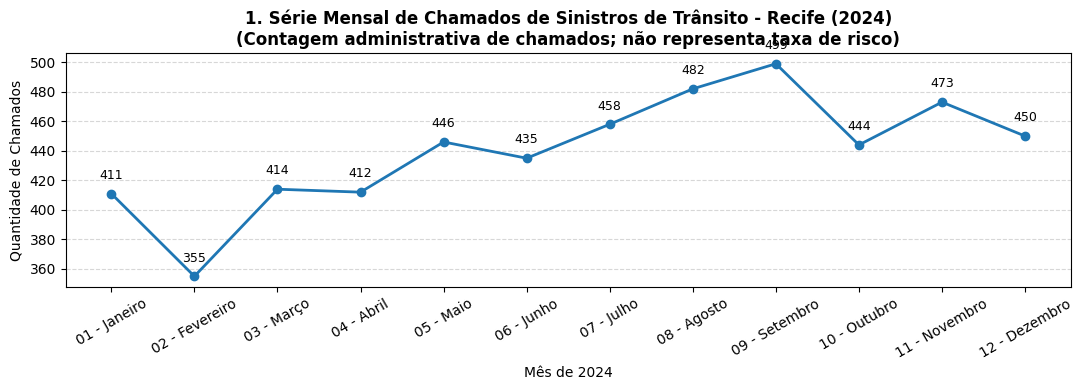

In [ ]:
import matplotlib.pyplot as plt

serie_mensal = (
    df_valid.groupby(["mes_num", "mes"], as_index=False)
    .agg(qtd_chamados=("protocolo", "count"))
    .sort_values("mes_num")
)

plt.figure(figsize=(11, 4))
plt.plot(serie_mensal["mes"], serie_mensal["qtd_chamados"], marker="o", linewidth=2, color="#1f77b4")
for _, row in serie_mensal.iterrows():
    plt.text(row["mes"], row["qtd_chamados"] + (serie_mensal["qtd_chamados"].max()*0.02), str(row["qtd_chamados"]), ha="center", fontsize=9)
plt.title("1. Série Mensal de Chamados de Sinistros de Trânsito - Recife (2024)\n(Contagem administrativa de chamados; não representa taxa de risco)", fontweight="bold")
plt.xlabel("Mês de 2024")
plt.ylabel("Quantidade de Chamados")
plt.xticks(rotation=30)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(f"{DIR_REPORTS}/grafico_01_serie_mensal_2024.png", dpi=150)
plt.show()

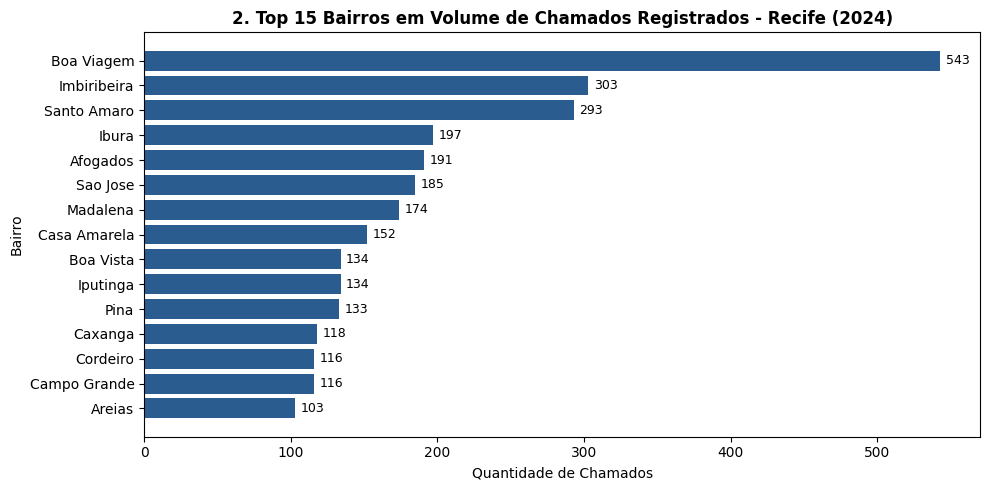

In [ ]:
top15_bairros = (
    df_valid.dropna(subset=["bairro"])
    .groupby("bairro", as_index=False)
    .agg(qtd_chamados=("protocolo", "count"))
    .sort_values("qtd_chamados", ascending=True)
    .tail(15)
)

plt.figure(figsize=(10, 5))
bars = plt.barh(top15_bairros["bairro"], top15_bairros["qtd_chamados"], color="#2b5c8f")
plt.bar_label(bars, padding=4, fontsize=9)
plt.title("2. Top 15 Bairros em Volume de Chamados Registrados - Recife (2024)", fontweight="bold")
plt.xlabel("Quantidade de Chamados")
plt.ylabel("Bairro")
plt.tight_layout()
plt.savefig(f"{DIR_REPORTS}/grafico_02_top15_bairros_2024.png", dpi=150)
plt.show()

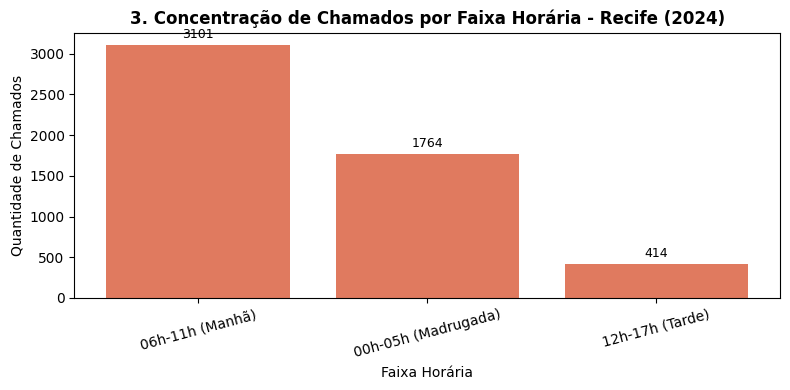

In [ ]:
faixa_df = (
    df_valid.groupby("faixa_horaria", as_index=False)
    .agg(qtd_chamados=("protocolo", "count"))
    .sort_values("qtd_chamados", ascending=False)
)

plt.figure(figsize=(8, 4))
bars_fh = plt.bar(faixa_df["faixa_horaria"], faixa_df["qtd_chamados"], color="#e07a5f")
plt.bar_label(bars_fh, padding=3, fontsize=9)
plt.title("3. Concentração de Chamados por Faixa Horária - Recife (2024)", fontweight="bold")
plt.xlabel("Faixa Horária")
plt.ylabel("Quantidade de Chamados")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(f"{DIR_REPORTS}/grafico_03_faixa_horaria_2024.png", dpi=150)
plt.show()

In [ ]:
from google.colab import drive
import shutil
import os

print("🔄 Iniciando backup de segurança do ETL 1 para o Google Drive...")

# 1. Montar o Google Drive
drive.mount('/content/drive')

# 2. Definir pasta de backup no seu Drive
backup_dir = "/content/drive/MyDrive/Backup_ETL1_Recife"
os.makedirs(backup_dir, exist_ok=True)

# 3. Copiar a pasta 'data' (onde o ETL 1 salva tudo)
if os.path.exists("data"):
    shutil.copytree("data", os.path.join(backup_dir, "data"), dirs_exist_ok=True)
    print("✅ Pasta 'data' (raw, processed, reports e banco .db) copiada com sucesso!")
else:
    print("⚠️ Pasta 'data' não encontrada.")
    print("   Isso pode significar que o ETL 1 ainda não foi executado nesta sessão.")

# 4. Copiar logs separados (se existirem)
if os.path.exists("logs"):
    shutil.copytree("logs", os.path.join(backup_dir, "logs"), dirs_exist_ok=True)
    print("✅ Pasta 'logs' copiada com sucesso!")
else:
    print("ℹ️ Pasta 'logs' não existe no ETL 1 (os logs ficam dentro de data/reports/).")

# 5. Listar o que foi salvo para conferência
print(f"\n📁 Conteúdo do backup em {backup_dir}:")
if os.path.exists(os.path.join(backup_dir, "data")):
    for item in os.listdir(os.path.join(backup_dir, "data")):
        print(f"   - data/{item}")

print(f"\n🎉 BACKUP CONCLUÍDO! Seus arquivos estão 100% seguros em:")
print(f"📁 {backup_dir}")
print("Você pode fechar o Colab tranquilamente agora.")

🔄 Iniciando backup de segurança do ETL 1 para o Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
⚠️ Pasta 'data' não encontrada.
   Isso pode significar que o ETL 1 ainda não foi executado nesta sessão.
ℹ️ Pasta 'logs' não existe no ETL 1 (os logs ficam dentro de data/reports/).

📁 Conteúdo do backup em /content/drive/MyDrive/Backup_ETL1_Recife:

🎉 BACKUP CONCLUÍDO! Seus arquivos estão 100% seguros em:
📁 /content/drive/MyDrive/Backup_ETL1_Recife
Você pode fechar o Colab tranquilamente agora.


In [ ]:
import os
import shutil
from google.colab import drive

print("🔄 Restaurando arquivos do Google Drive para o ambiente local do Colab...")

# 1. Montar o Drive (se ainda não estiver montado)
drive.mount('/content/drive')

# 2. Definir caminhos
backup_dir = "/content/drive/MyDrive/Backup_ETL1_Recife"
local_dir = "./data"

# 3. Copiar os arquivos de volta
if os.path.exists(backup_dir):
    # Remove a pasta local se existir para evitar conflitos de merge
    if os.path.exists(local_dir):
        shutil.rmtree(local_dir)

    # Copia a pasta inteira (raw, processed, reports e o banco .db)
    shutil.copytree(backup_dir, local_dir)

    print(f"\n✅ SUCESSO! Os arquivos foram restaurados em: {os.path.abspath(local_dir)}")
    print("   Conteúdo da pasta:", os.listdir(local_dir))
    print("\nAgora você pode rodar os blocos de análise ou integração normalmente!")
else:
    print("\n❌ ERRO: A pasta de backup não foi encontrada no Google Drive.")

🔄 Restaurando arquivos do Google Drive para o ambiente local do Colab...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

✅ SUCESSO! Os arquivos foram restaurados em: /content/data
   Conteúdo da pasta: ['mobilidade_recife.db', 'raw', 'reports', 'processed']

Agora você pode rodar os blocos de análise ou integração normalmente!
